# Regularization and Gradient Descent Exercises
![UnderOverFit.png](Assets/UnderOverFit.png)


# Obiectivele învățării

- Explicarea funcțiilor de cost, regularizarea, selectarea caracteristicilor și hiperparametrii
- Rezumarea algoritmilor de optimizare statistică complexă, cum ar fi coborârea gradientului și aplicarea sa la regresia liniară



## Introducere

Vom începe cu un scurt tutorial despre regresie, caracteristici polinomiale și regularizare, bazat pe un set de date foarte simplu, rar, care conține o coloană de date `x` și date zgomotoase asociate `y`. Fișierul de date se numește `X_Y_Sinusoid_Data.csv`. 

In [1]:
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')
data_path = ['data']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import Ridge, Lasso
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LassoCV
from sklearn.linear_model import ElasticNetCV
from sklearn.preprocessing import MinMaxScaler

## Întrebare 1

* Importați datele. 

* De asemenea, generați aproximativ 100 de puncte de date x egal distanțate pe intervalul 0-1. Folosind aceste puncte, calculați datele y care reprezintă „adevărul de bază” (funcția reală) din ecuația: $y = sin(2\pi x)$

* Reprezentați grafic datele rarefiate (`x` vs `y`) și datele calculate („reale”).


In [2]:
# Importam datele rare
filepath = 'X_Y_Sinusoid_Data - X_Y_Sinusoid_Data.csv'
data = pd.read_csv(filepath)

print(data.shape)
data.head()

(20, 2)


,x,y
0,0.038571,0.066391
1,0.166776,1.027483
2,0.183153,1.245302
3,0.187359,1.004781
4,0.243116,1.264121


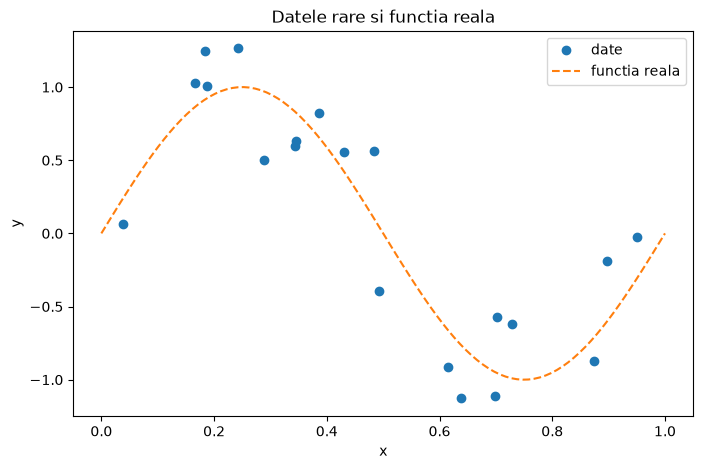

In [3]:
# 100 de puncte egal distantate in [0, 1] si functia reala y = sin(2*pi*x)
X_real = np.linspace(0, 1.0, 100)
Y_real = np.sin(2 * np.pi * X_real)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(data['x'], data['y'], 'o', label='date')
ax.plot(X_real, Y_real, ls='--', label='functia reala')
ax.set(xlabel='x', ylabel='y', title='Datele rare si functia reala')
ax.legend()
plt.show()

## Întrebarea 2


* Folosind clasa `PolynomialFeatures` din biblioteca de preprocesare Scikit-learn, creați caracteristici polinomiale de ordinul 20.
* Adaptați aceste date folosind regresia liniară. 
* Reprezentați grafic valoarea prezisă rezultată în comparație cu datele calculate.

Rețineți că `PolynomialFeatures` necesită fie un cadru de date (cu o coloană, nu o serie), fie o matrice 2D de dimensiune (`X`, 1), unde `X` este lungimea.

In [4]:
# Caracteristici polinomiale de ordinul 20
degree = 20
pf = PolynomialFeatures(degree)
lr = LinearRegression()

# PolynomialFeatures cere un DataFrame cu o coloana (nu o Series)
X_data = data[['x']]
Y_data = data['y']

X_poly = pf.fit_transform(X_data)
print('Forma X_poly:', X_poly.shape)

lr = lr.fit(X_poly, Y_data)

# Predictia pe punctele "reale"
X_real_poly = pf.transform(pd.DataFrame({'x': X_real}))
Y_pred = lr.predict(X_real_poly)

Forma X_poly: (20, 21)


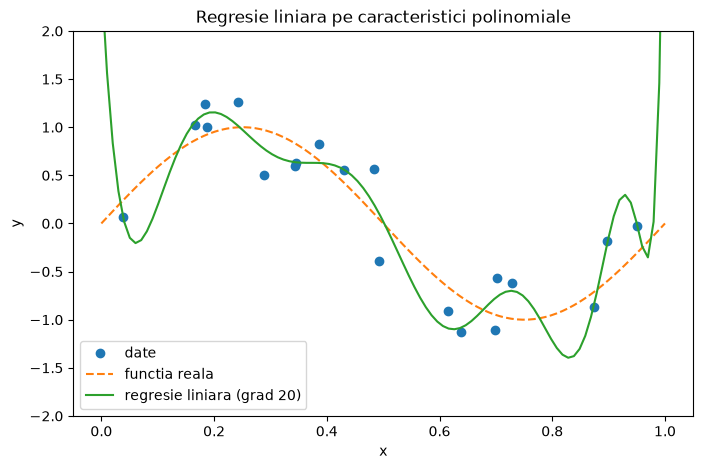

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(data['x'], data['y'], 'o', label='date')
ax.plot(X_real, Y_real, ls='--', label='functia reala')
ax.plot(X_real, Y_pred, label='regresie liniara (grad 20)')
# Limitam axa y, altfel oscilatiile modelului ascund restul graficului
ax.set(xlabel='x', ylabel='y', ylim=(-2, 2), title='Regresie liniara pe caracteristici polinomiale')
ax.legend()
plt.show()

## Întrebare 3

* Efectuați regresia pe baza datelor cu caracteristici polinomiale utilizând regresia Ridge ($\alpha$=0,001) și regresia Lasso ($\alpha$=0,0001). 
* Reprezentați grafic rezultatele, așa cum s-a făcut la întrebarea 1. 
* De asemenea, reprezentați grafic magnitudinea coeficienților obținuți din aceste regresii și comparați-i cu cei obținuți din regresia liniară din întrebarea anterioară. Coeficienții regresiei liniare vor necesita probabil un grafic separat (sau propria axă y) din cauza magnitudinii lor mari. 

Ce vă spune magnitudinea comparativ mare a datelor cu privire la rolul regularizării?

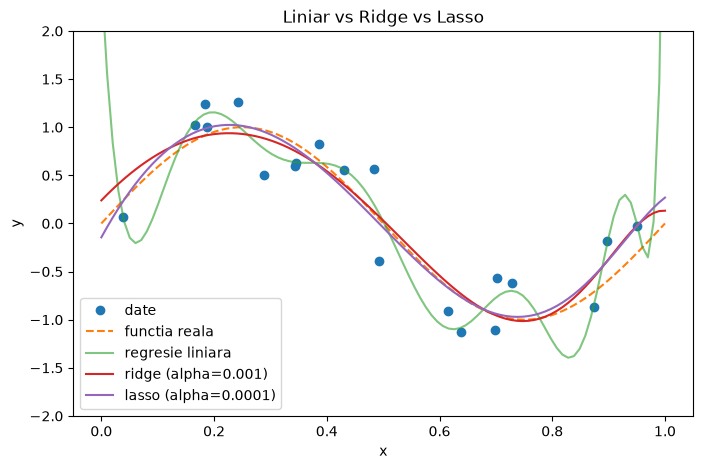

In [6]:
# Ridge (L2) si Lasso (L1) pe aceleasi caracteristici polinomiale
rr = Ridge(alpha=0.001)
rr = rr.fit(X_poly, Y_data)
Y_pred_rr = rr.predict(X_real_poly)

# Lasso converge greu pe caracteristici nescalate, deci marim max_iter
lassor = Lasso(alpha=0.0001, max_iter=100000)
lassor = lassor.fit(X_poly, Y_data)
Y_pred_lr = lassor.predict(X_real_poly)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(data['x'], data['y'], 'o', label='date')
ax.plot(X_real, Y_real, ls='--', label='functia reala')
ax.plot(X_real, Y_pred, label='regresie liniara', alpha=0.6)
ax.plot(X_real, Y_pred_rr, label='ridge (alpha=0.001)')
ax.plot(X_real, Y_pred_lr, label='lasso (alpha=0.0001)')
ax.set(xlabel='x', ylabel='y', ylim=(-2, 2), title='Liniar vs Ridge vs Lasso')
ax.legend()
plt.show()

In [7]:
# let's look at the absolute value of coefficients for each model

coefficients = pd.DataFrame()
coefficients['linear regression'] = lr.coef_.ravel()
coefficients['ridge regression'] = rr.coef_.ravel()
coefficients['lasso regression'] = lassor.coef_.ravel()
# applymap a fost eliminat in pandas 3, folosim abs() direct
coefficients = coefficients.abs()

coefficients.describe()  # Huge difference in scale between non-regularized vs regularized regression

,linear regression,ridge regression,lasso regression
count,2.100000e+01,21.000000,21.000000
mean,1.046973e+04,2.169397,2.665181
std,6.883591e+03,2.900278,6.772431
min,4.542817e-07,0.000000,0.000000
25%,5.224863e+03,0.467578,0.000000
50%,1.087741e+04,1.017272,0.000000
75%,1.529173e+04,2.883507,0.000000
max,2.316913e+04,12.429635,25.359652


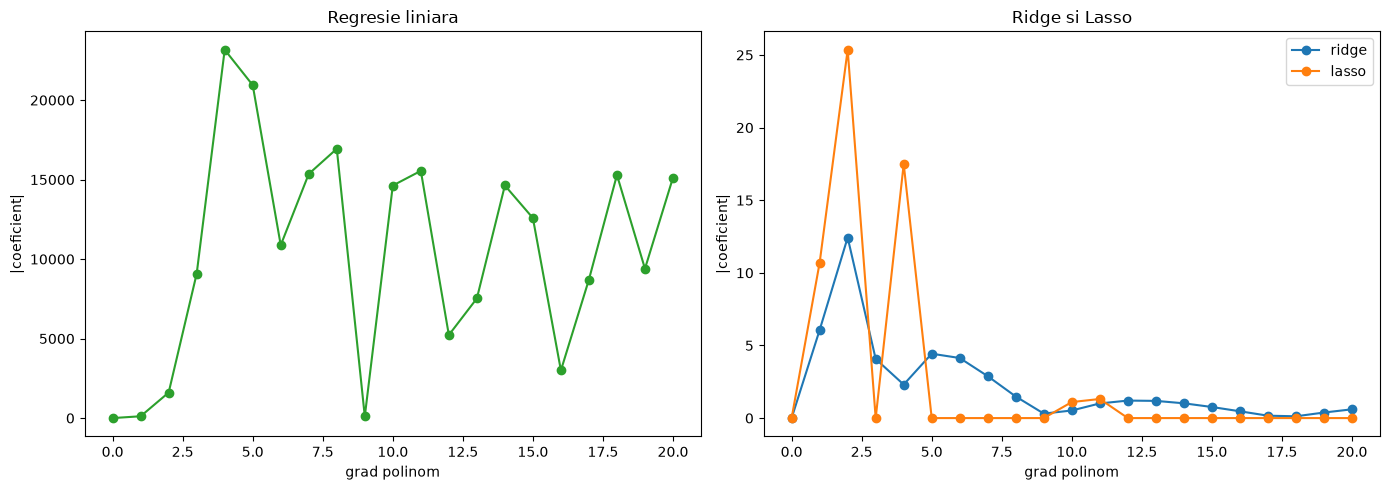

Coeficienti nenuli Lasso: 5 din 21


In [8]:
# Magnitudinea coeficientilor; regresia liniara are axa ei din cauza valorilor foarte mari
fig, axList = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))
ax1, ax2 = axList

ax1.plot(coefficients['linear regression'], marker='o', color='C2')
ax1.set(xlabel='grad polinom', ylabel='|coeficient|', title='Regresie liniara')

ax2.plot(coefficients['ridge regression'], marker='o', label='ridge')
ax2.plot(coefficients['lasso regression'], marker='o', label='lasso')
ax2.set(xlabel='grad polinom', ylabel='|coeficient|', title='Ridge si Lasso')
ax2.legend()

plt.tight_layout()
plt.show()

print('Coeficienti nenuli Lasso:', (lassor.coef_ != 0).sum(), 'din', len(lassor.coef_))

**Raspuns:** Coeficientii regresiei liniare nepenalizate ajung la valori de ordinul zecilor de mii (pana la ~2*10^4), iar cei ai modelelor Ridge si Lasso raman mici (sub ~30). Modelul liniar "memoreaza" cele cateva puncte zgomotoase cu un polinom de grad 20 care oscileaza puternic intre ele (supraadaptare). Regularizarea penalizeaza marimea coeficientilor, ceea ce reduce varianta modelului si produce o curba neteda, mult mai apropiata de functia reala $\sin(2\pi x)$. In plus, Lasso (L1) anuleaza o parte din coeficienti, adica face si selectie de caracteristici.

## Întrebarea 4

Pentru întrebările rămase, vom lucra cu [setul de date](https://www.kaggle.com/c/house-prices-advanced-regression-techniques) din lecția trecută, care se bazează pe prețurile locuințelor din Ames, Iowa. Există un număr mare de caracteristici - a se vedea exercițiile din săptămâna a treia pentru o discuție despre aceste caracteristici.

Pentru a începe:

* Importați datele cu Pandas, eliminați orice valori nule și o codificare fierbinte a categoriilor. Pot fi utilizate fie codificatoarele de caracteristici Scikit-learn, fie metoda Pandas `get_dummies`.
* Împărțiți datele în seturi de instruire și de testare. 
* Transformarea logaritmică a caracteristicilor distorsionate. 
* Se poate încerca scalarea, deși poate fi interesant să se vadă cât de bine funcționează regularizarea fără scalarea caracteristicilor.

In [9]:
filepath = 'Ames_Housing_Sales.csv'
data = pd.read_csv(filepath, sep=',')

print(data.shape)
data.dtypes.value_counts()

(1379, 80)


str        43
float64    21
int64      16
Name: count, dtype: int64

Creați o listă de date categoriale și codificați one-hot. Pandas one-hot encoder (`get_dummies`) funcționează bine cu date care sunt definite ca fiind categoriale.

In [10]:
# Valorile lipsa apar doar in coloanele text si inseamna "nu exista"
# (fara alee, fara piscina etc.), deci le inlocuim cu o categorie separata
categorical_cols = data.select_dtypes(include=['object', 'string']).columns
print(data.isna().sum().loc[lambda s: s > 0])
data[categorical_cols] = data[categorical_cols].fillna('None')

# Retinem coloanele numerice originale (inainte de codificare)
numeric_cols = data.select_dtypes(include='number').columns

# Codificare one-hot cu pandas
data = pd.get_dummies(data, columns=categorical_cols, drop_first=True, dtype=int)

print('Valori lipsa ramase:', data.isna().sum().sum())
print(data.shape)

Alley           1297
BsmtCond         426
BsmtExposure     426
BsmtFinType1     426
BsmtFinType2     427
BsmtQual         426
Fence           1114
FireplaceQu      618
MasVnrType       797
MiscFeature     1328
PoolQC          1372
dtype: int64
Valori lipsa ramase: 0
(1379, 252)


Apoi, împărțiți datele în seturi de date de instruire și de testare.

In [11]:
train, test = train_test_split(data, test_size=0.3, random_state=42)
print(train.shape, test.shape)

(965, 252) (414, 252)


Există o serie de coloane care au caracteristici înclinate - li se poate aplica o transformare logaritmică. Rețineți că aceasta include `SalePrice`, predictorul nostru. Cu toate acestea, să o păstrăm așa cum este.

In [12]:
# Asimetria (skew) se calculeaza doar pe coloanele numerice originale, din setul de antrenare
skew_vals = train[numeric_cols].skew()

# Coloanele cu asimetrie > 0.75, fara SalePrice
skew_cols = (skew_vals
             .sort_values(ascending=False)
             .to_frame()
             .rename(columns={0: 'Skew'})
             .query('abs(Skew) > 0.75'))
skew_cols = skew_cols.drop('SalePrice', errors='ignore')
skew_cols

,Skew
MiscVal,26.915364
PoolArea,15.777668
LotArea,11.501694
LowQualFinSF,11.210638
3SsnPorch,10.150612
KitchenAbvGr,5.497813
ScreenPorch,4.599803
BsmtFinSF2,4.466378
BsmtHalfBath,3.882163
EnclosedPorch,3.218303


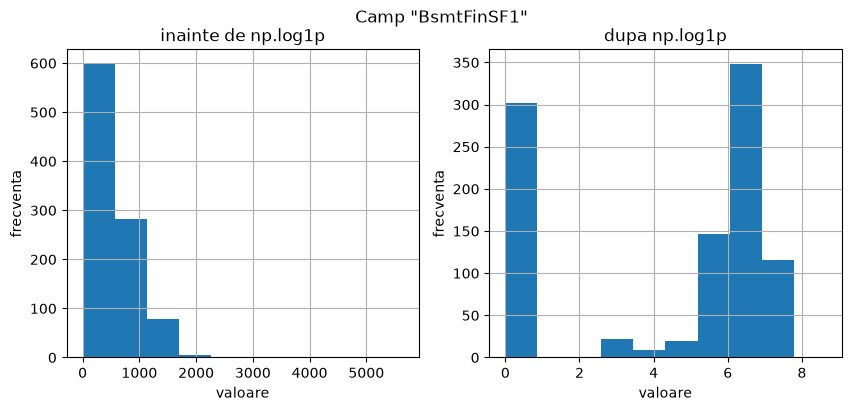

In [13]:
# Exemplu de transformare: inainte si dupa log1p
field = 'BsmtFinSF1'
fig, (ax_before, ax_after) = plt.subplots(1, 2, figsize=(10, 4))
train[field].hist(ax=ax_before)
train[field].apply(np.log1p).hist(ax=ax_after)
ax_before.set(title='inainte de np.log1p', ylabel='frecventa', xlabel='valoare')
ax_after.set(title='dupa np.log1p', ylabel='frecventa', xlabel='valoare')
fig.suptitle('Camp "{}"'.format(field))
plt.show()

Transformați toate coloanele în care deviația este mai mare de 0,75, cu excepția „SalePrice”.

In [14]:
# Transformarea logaritmica (log1p, deoarece exista valori 0) pe ambele seturi
for col in skew_cols.index.values:
    train[col] = train[col].apply(np.log1p)
    test[col] = test[col].apply(np.log1p)

print('Coloane transformate:', len(skew_cols))

Coloane transformate: 23


Separați datele dupa predictor

In [15]:
feature_cols = [x for x in train.columns if x != 'SalePrice']
X_train = train[feature_cols]
y_train = train['SalePrice']

X_test = test[feature_cols]
y_test = test['SalePrice']

print(X_train.shape, X_test.shape)

(965, 251) (414, 251)


## Întrebare 5

* Scrieți o funcție **`rmse`** care primește valorile de adevăr și predicție și returnează eroarea medie pătratică. Utilizați funcția `mean_squared_error` de la sklearn.  


In [16]:
def rmse(ytrue, ypredicted):
    return np.sqrt(mean_squared_error(ytrue, ypredicted))

* Adaptați un model de regresie liniară de bază
* tipăriți eroarea medie pătratică pentru acest model
* reprezentați grafic prețul de vânzare previzionat față de cel real pe baza modelului.  

In [17]:
linearRegression = LinearRegression().fit(X_train, y_train)

linearRegression_rmse = rmse(y_test, linearRegression.predict(X_test))

print('RMSE regresie liniara: {:.2f}'.format(linearRegression_rmse))

RMSE regresie liniara: 78634.29


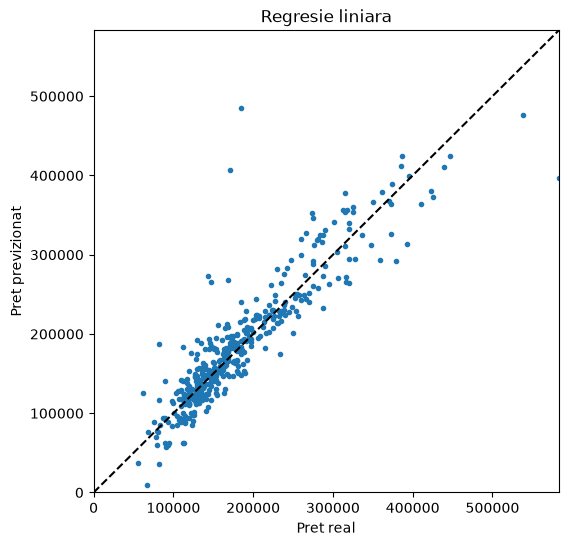

In [18]:
f = plt.figure(figsize=(6, 6))
ax = plt.axes()

ax.plot(y_test, linearRegression.predict(X_test),
        marker='o', ls='', ms=3.0)

lim = (0, y_test.max())

ax.set(xlabel='Pret real',
       ylabel='Pret previzionat',
       xlim=lim,
       ylim=lim,
       title='Regresie liniara')
# Diagonala = predictie perfecta
ax.plot(lim, lim, color='k', ls='--')
plt.show()

## Întrebarea 6

Regresia Ridge utilizează normalizarea L2 pentru a reduce magnitudinea coeficienților. Acest lucru poate fi util în situații în care există o varianță ridicată. Funcțiile de regularizare din Scikit-learn conțin fiecare versiuni care au validarea încrucișată încorporată.

* Adaptați un model Ridge regulat (nevalidat încrucișat) la o gamă de valori $\alpha$ și reprezentați grafic RMSE utilizând funcția de eroare validată încrucișat pe care ați creat-o mai sus.
* Utilizați $$[0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]$$ ca interval de alphas.
* Apoi repetați ajustarea modelelor Ridge folosind gama de valori $\alpha$ din secțiunea anterioară. Comparați rezultatele.

In [19]:
alphas = [0.005, 0.05, 0.1, 0.3, 1, 3, 5, 10, 15, 30, 80]

# Ridge simplu (fara validare incrucisata) pentru fiecare alpha:
# RMSE pe setul de test si RMSE din validarea incrucisata pe setul de antrenare
ridge_results = []
for alpha in alphas:
    ridge = Ridge(alpha=alpha).fit(X_train, y_train)
    test_rmse = rmse(y_test, ridge.predict(X_test))
    cv_rmse = np.sqrt(-cross_val_score(Ridge(alpha=alpha), X_train, y_train,
                                       scoring='neg_mean_squared_error', cv=4)).mean()
    ridge_results.append({'alpha': alpha, 'RMSE test': test_rmse, 'RMSE CV': cv_rmse})

ridge_results = pd.DataFrame(ridge_results).set_index('alpha')
ridge_results.round(1)

,RMSE test,RMSE CV
alpha,,
0.005,42163.9,35253.4
0.050,40923.9,34327.3
0.100,39780.7,33801.7
0.300,37188.0,33057.1
1.000,34395.0,32546.1
3.000,32889.6,31985.8
5.000,32495.1,31737.9
10.000,32205.8,31611.4
15.000,32166.7,31722.6


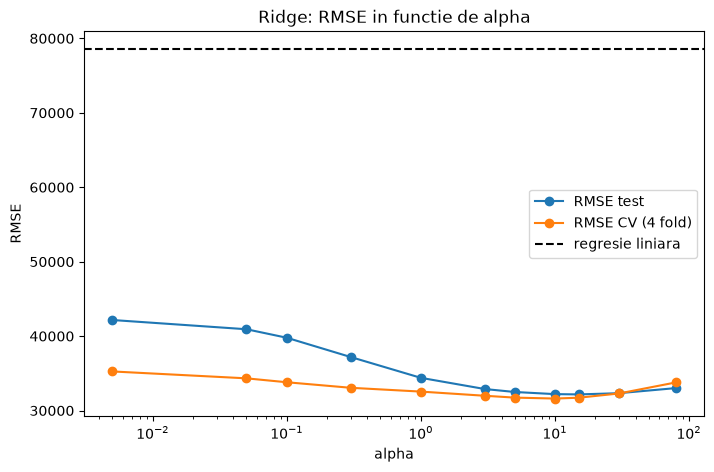

Cel mai bun alpha dupa CV: 10.0


In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogx(ridge_results.index, ridge_results['RMSE test'], marker='o', label='RMSE test')
ax.semilogx(ridge_results.index, ridge_results['RMSE CV'], marker='o', label='RMSE CV (4 fold)')
ax.axhline(linearRegression_rmse, color='k', ls='--', label='regresie liniara')
ax.set(xlabel='alpha', ylabel='RMSE', title='Ridge: RMSE in functie de alpha')
ax.legend()
plt.show()

print('Cel mai bun alpha dupa CV:', ridge_results['RMSE CV'].idxmin())

Acum, pentru metoda `RidgeCV`. Din păcate, nu este posibil să obținem valorile alfa pentru modelele care nu au fost selectate. Valorile erorilor și valorile $\alpha$ rezultate sunt foarte asemănătoare cu cele obținute mai sus.

In [21]:
ridgeCV = RidgeCV(alphas=alphas, cv=4).fit(X_train, y_train)

ridgeCV_rmse = rmse(y_test, ridgeCV.predict(X_test))

print('alpha optim:', ridgeCV.alpha_)
print('RMSE RidgeCV: {:.2f}'.format(ridgeCV_rmse))

alpha optim: 10.0
RMSE RidgeCV: 32205.83


**Comparatie:** `RidgeCV` alege acelasi $\alpha$ ca bucla manuala cu validare incrucisata (cea mai mica valoare RMSE CV), iar eroarea pe test este practic aceeasi. Toate modelele Ridge au RMSE mai mic decat regresia liniara simpla, deci regularizarea L2 ajuta pe acest set de date cu multe caracteristici.

## Întrebarea 7


La fel ca funcția `RidgeCV`, există și o funcție `LassoCV` care utilizează o funcție de regularizare L1 și validarea încrucișată. Regularizarea L1 va micșora selectiv anumiți coeficienți, efectuând efectiv eliminarea caracteristicilor.

Funcția `LassoCV` nu permite setarea funcției de scor. Cu toate acestea, funcția de eroare personalizată (`rmse`) creată mai sus poate fi utilizată pentru a evalua eroarea modelului final.

În mod similar, există și o funcție elastic net cu validare încrucișată, `ElasticNetCV`, care este o combinație de regularizare L2 și L1.

* Potriviți un model Lasso utilizând validarea încrucișată și determinați valoarea optimă pentru $\alpha$ și RMSE utilizând funcția creată mai sus. Rețineți că magnitudinea lui $\alpha$ poate fi diferită de cea a modelului Ridge.
* Repetați operația cu modelul de plasă elastică.
* Comparați rezultatele prin tabel și/sau grafic.

Utilizați următoarele alphas:

`[1e-5, 5e-5, 0.0001, 0.0005]`

In [22]:
alphas2 = np.array([1e-5, 5e-5, 0.0001, 0.0005])

lassoCV = LassoCV(alphas=alphas2,
                  max_iter=50000,
                  cv=3).fit(X_train, y_train)

lassoCV_rmse = rmse(y_test, lassoCV.predict(X_test))

print('alpha optim:', lassoCV.alpha_)
print('RMSE LassoCV: {:.2f}'.format(lassoCV_rmse))

alpha optim: 0.0005
RMSE LassoCV: 89886.14


Putem determina câte dintre aceste caracteristici rămân diferite de zero.

In [23]:
print('Din {} coeficienti, {} sunt nenuli cu Lasso.'.format(len(lassoCV.coef_),
                                                            (lassoCV.coef_ != 0).sum()))

Din 251 coeficienti, 240 sunt nenuli cu Lasso.


Încercați acum plasa elastică, cu aceleași alphas ca în Lasso, și l1_ratios între 0,1 și 0,9

In [24]:
l1_ratios = np.linspace(0.1, 0.9, 9)

elasticNetCV = ElasticNetCV(alphas=alphas2,
                            l1_ratio=l1_ratios,
                            max_iter=10000,
                            cv=3).fit(X_train, y_train)
elasticNetCV_rmse = rmse(y_test, elasticNetCV.predict(X_test))

print('alpha optim:', elasticNetCV.alpha_)
print('l1_ratio optim:', elasticNetCV.l1_ratio_)
print('RMSE ElasticNetCV: {:.2f}'.format(elasticNetCV_rmse))

alpha optim: 0.0005
l1_ratio optim: 0.1
RMSE ElasticNetCV: 36243.29


Compararea calculului RMSE din toate modelele este cea mai ușoară într-un tabel.

In [25]:
rmse_vals = [linearRegression_rmse, ridgeCV_rmse, lassoCV_rmse, elasticNetCV_rmse]

labels = ['Linear', 'Ridge', 'Lasso', 'ElasticNet']

rmse_df = pd.Series(rmse_vals, index=labels).to_frame()
rmse_df.rename(columns={0: 'RMSE'}, inplace=True)
rmse_df

,RMSE
Linear,78634.285806
Ridge,32205.825151
Lasso,89886.136455
ElasticNet,36243.288512


**Observatie:** Ridge are cea mai mica eroare, urmat de ElasticNet. Lasso iese chiar mai slab decat regresia liniara: valorile $\alpha$ date (maxim 0.0005) sunt foarte mici fata de scara pretului (sute de mii de dolari) si a caracteristicilor nescalate, deci penalizarea L1 aproape nu are efect (raman 240 din 251 coeficienti nenuli) si modelul se comporta ca o regresie liniara nepenalizata, care supraadapteaza. ElasticNet alege `l1_ratio=0.1`, adica in principal componenta L2, si de aceea se apropie de Ridge.

Putem, de asemenea, să realizăm un grafic al prețurilor reale și previzionate ale locuințelor, la fel ca înainte.

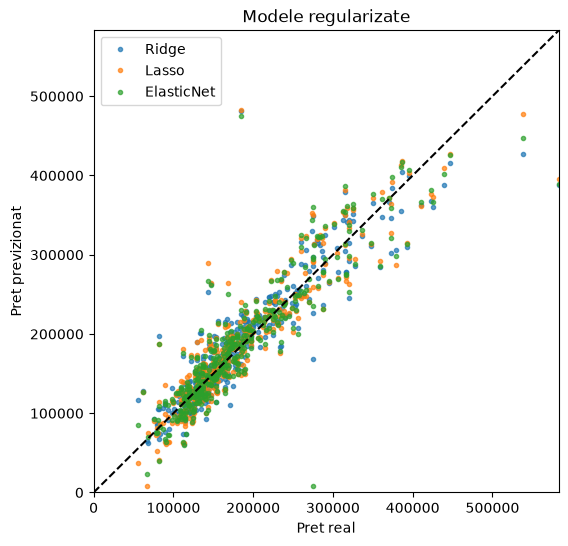

In [26]:
f = plt.figure(figsize=(6, 6))
ax = plt.axes()

labels = ['Ridge', 'Lasso', 'ElasticNet']
models = [ridgeCV, lassoCV, elasticNetCV]

for mod, lab in zip(models, labels):
    ax.plot(y_test, mod.predict(X_test),
            marker='o', ls='', ms=3.0, label=lab, alpha=0.7)

lim = (0, y_test.max())
ax.plot(lim, lim, color='k', ls='--')
ax.set(xlabel='Pret real',
       ylabel='Pret previzionat',
       xlim=lim,
       ylim=lim,
       title='Modele regularizate')
ax.legend()
plt.show()

## Întrebarea 8

Să explorăm coborârea stochastică a gradientului în acest exercițiu.  
Reamintim că modelele liniare în general sunt sensibile la scalare.
Cu toate acestea, SGD este *foarte* sensibil la scalare.  
În plus, o valoare mare a ratei de învățare poate determina algoritmul să devieze, în timp ce o valoare prea mică poate dura prea mult până la convergență.

* Potriviți un model stochastic gradient descent fără o penalizare de regularizare (parametrul relevant este `penalty`).
* Ajustați acum modele stochastice de coborâre în gradient cu fiecare dintre cele trei penalizări (L2, L1, Elastic Net) folosind valorile parametrilor determinate prin validarea încrucișată de mai sus. 
* Nu scalați datele înainte de ajustarea modelului.  
* Comparați rezultatele cu cele obținute fără a utiliza coborârea stochastică în gradient.

In [27]:
# Parametrii pentru fiecare penalizare, determinati prin validare incrucisata mai sus
model_parameters_dict = {
    'Linear': {'penalty': None},
    'Lasso': {'penalty': 'l1',
              'alpha': lassoCV.alpha_},
    'Ridge': {'penalty': 'l2',
              'alpha': ridgeCV.alpha_},
    'ElasticNet': {'penalty': 'elasticnet',
                   'alpha': elasticNetCV.alpha_,
                   'l1_ratio': elasticNetCV.l1_ratio_}
}


def fit_sgd(params, Xtr, ytr, Xte, yte):
    # Pe date nescalate algoritmul poate diverge pana la overflow;
    # in acest caz sklearn arunca ValueError si marcam eroarea ca infinita
    try:
        sgd = SGDRegressor(random_state=42, **params).fit(Xtr, ytr)
        return rmse(yte, sgd.predict(Xte))
    except ValueError as e:
        print('  divergenta:', str(e).split('.')[0])
        return np.inf


new_rmses = {}
for modellabel, parameters in model_parameters_dict.items():
    print(modellabel)
    new_rmses[modellabel] = fit_sgd(parameters, X_train, y_train, X_test, y_test)

rmse_df['RMSE-SGD'] = pd.Series(new_rmses)
rmse_df

Linear
Lasso
Ridge


ElasticNet


,RMSE,RMSE-SGD
Linear,78634.285806,5.774759e+15
Ridge,32205.825151,4.938913e+15
Lasso,89886.136455,5.272621e+14
ElasticNet,36243.288512,6.618047e+14


Observați cât de mari sunt valorile erorii! Algoritmul este divergent. Acest lucru se poate datora faptului că scalarea și/sau rata de învățare sunt prea mari. Să ajustăm rata de învățare și să vedem ce se întâmplă.

* Introduceți `eta0=1e-7` la crearea instanței de `SGDClassifier`.
* Calculați din nou erorile pentru toate penalitățile și comparați.

In [28]:
# Aceleasi modele, dar cu o rata de invatare initiala foarte mica
new_rmses = {}
for modellabel, parameters in model_parameters_dict.items():
    print(modellabel)
    params = parameters.copy()
    params['eta0'] = 1e-7
    new_rmses[modellabel] = fit_sgd(params, X_train, y_train, X_test, y_test)

rmse_df['RMSE-SGD-learningrate'] = pd.Series(new_rmses)
rmse_df

Linear
Lasso
Ridge
ElasticNet


,RMSE,RMSE-SGD,RMSE-SGD-learningrate
Linear,78634.285806,5.774759e+15,74750.079681
Ridge,32205.825151,4.938913e+15,74753.068847
Lasso,89886.136455,5.272621e+14,74750.079686
ElasticNet,36243.288512,6.618047e+14,74750.079816


Acum să ne scalăm datele de antrenament și să încercăm din nou.

* Adaptați un `MinMaxScaler` la `X_train` și creați o variabilă `X_train_scaled`.
* Folosind scala, transformați `X_test` și creați o variabilă `X_test_scaled`. 
* Aplicați-le aceleași versiuni ale SGD și comparați rezultatele. De data aceasta nu introduceți un eta0.

In [29]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
# Scalerul invatat pe antrenare se aplica si pe test
X_test_scaled = scaler.transform(X_test)

new_rmses = {}
for modellabel, parameters in model_parameters_dict.items():
    print(modellabel)
    new_rmses[modellabel] = fit_sgd(parameters, X_train_scaled, y_train, X_test_scaled, y_test)

rmse_df['RMSE-SGD-scaled'] = pd.Series(new_rmses)
rmse_df.round(1)

Linear
Lasso


Ridge
ElasticNet


,RMSE,RMSE-SGD,RMSE-SGD-learningrate,RMSE-SGD-scaled
Linear,78634.3,5.774759e+15,74750.1,32674.9
Ridge,32205.8,4.938913e+15,74753.1,70586.2
Lasso,89886.1,5.272621e+14,74750.1,32674.9
ElasticNet,36243.3,6.618047e+14,74750.1,32643.2


**Concluzii:**

- Pe datele nescalate, SGD cu rata de invatare implicita diverge (RMSE de ordinul 10^14 - 10^15), indiferent de penalizare.
- Cu `eta0=1e-7` algoritmul nu mai diverge, dar toate penalizarile dau aproape aceeasi eroare (~75000): pasii sunt atat de mici incat modelul nu ajunge la optim, iar eroarea ramane mult peste Ridge sau ElasticNet.
- Dupa scalarea cu `MinMaxScaler`, SGD fara penalizare, cu L1 si cu Elastic Net ajunge la ~32600, comparabil cu cel mai bun model (RidgeCV). Exceptie face L2: `alpha=10` ales de RidgeCV este mult prea mare pentru SGD (alt model, alta scara a datelor), deci penalizarea comprima excesiv coeficientii. Parametrii optimi nu se transfera automat intre modele diferite.
- Concluzia: SGD este foarte sensibil la scalarea datelor si la rata de invatare.